<a href="https://colab.research.google.com/github/nyarotoyi/Credit-Risk-Statistical-Learning/blob/main/Practical2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name : Marice Ziana Otoyi

Course : Msc Artificial Intelligence

Reg: GMAI/ON/4355/09/26

Course : MSAI 713

Statistical Learning

Email : motoyi@kabarak.ac.ke

Practical 2

Date : 12/10/2026


# Import the Necessary libraries


In [ ]:

# Import libraries for data manipulation and analysis
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent style for our plots
sns.set_theme(style="whitegrid")

# Display all columns when viewing the dataset
pd.set_option("display.max_columns", None)


# Task 1: Exploratory Data Analysis (EDA)

We explore the credit risk dataset to understand its structure, identify skewness, outliers, potential non-linear relationships, and class imbalance. These findings will help us assess the suitability of parametric and non-parametric models.

## Load the dataset


In this step, load the synthetic credit risk dataset directly from my GitHub repository.

Using GitHub allows the dataset to be accessed without relying on files stored in my personal Google Drive.

 I also examine the first five observations and check the dataset dimensions to confirm that the data is loaded successfully.

In [ ]:
# Loading the credit risk dataset from GitHub
url = "https://raw.githubusercontent.com/nyarotoyi/Credit-Risk-Statistical-Learning/refs/heads/main/synthetic_credit_risk.csv"

df = pd.read_csv(url)

# Display the first five rows
df.head()

,Age,Monthly_Income,Income_Variance,Loan_Amount,Loan_Term,Credit_History_Length,Previous_Defaults,Default
0,42,7065.437962,2.036999,2570.159623,48,0,0,1
1,36,2952.398480,2.448294,2271.165054,36,20,3,1
2,44,4262.761489,0.821935,2000.000000,36,29,0,0
3,53,3049.200874,0.508102,4319.789578,12,22,0,0
4,35,3100.449139,1.134828,2000.000000,12,25,0,0


In [ ]:
# Check the dimensions of the dataset
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the first five observations
display(df.head())

Dataset shape: (800, 8)

Column names:
['Age', 'Monthly_Income', 'Income_Variance', 'Loan_Amount', 'Loan_Term', 'Credit_History_Length', 'Previous_Defaults', 'Default']


,Age,Monthly_Income,Income_Variance,Loan_Amount,Loan_Term,Credit_History_Length,Previous_Defaults,Default
0,42,7065.437962,2.036999,2570.159623,48,0,0,1
1,36,2952.398480,2.448294,2271.165054,36,20,3,1
2,44,4262.761489,0.821935,2000.000000,36,29,0,0
3,53,3049.200874,0.508102,4319.789578,12,22,0,0
4,35,3100.449139,1.134828,2000.000000,12,25,0,0


# Understanding the Dataset

We're checking:
- Number of observations and variables.
- Whether variables have appropriate data types.
- Whether any columns have missing values.

In [ ]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Examine the column names, data types and non-null values
df.info()

# Check for missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Check for duplicate records
print("\nNumber of duplicate records:")
print(df.duplicated().sum())

Dataset shape: (800, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    800 non-null    int64  
 1   Monthly_Income         800 non-null    float64
 2   Income_Variance        800 non-null    float64
 3   Loan_Amount            800 non-null    float64
 4   Loan_Term              800 non-null    int64  
 5   Credit_History_Length  800 non-null    int64  
 6   Previous_Defaults      800 non-null    int64  
 7   Default                800 non-null    int64  
dtypes: float64(3), int64(5)
memory usage: 50.1 KB
Missing values per column:
Age                      0
Monthly_Income           0
Income_Variance          0
Loan_Amount              0
Loan_Term                0
Credit_History_Length    0
Previous_Defaults        0
Default                  0
dtype: int64

Number of duplicate records:
0


The dataset contains **800 observations and 8 variables**, comprising seven predictor variables and one target variable (`Default`), which indicates whether an applicant defaulted on their loan.

All variables are numerical, with five stored as integers (`int64`) and three as floating-point numbers (`float64`). The data types are appropriate for the variables represented. The target variable is stored as an integer, with 0 representing loans that were repaid and 1 representing loans that defaulted.

All eight variables have 800 non-null observations, meaning **there are no missing values** in the dataset. Therefore, no missing-value imputation is required at this stage.

The dataset is sufficiently structured to proceed with exploratory analysis and model development. However, the absence of missing values does not necessarily mean the data is free from other quality issues, such as outliers or unusual distributions.

In the next step, I examine the descriptive statistics and variable distributions to identify potential skewness, outliers, and patterns that may influence the suitability of parametric and non-parametric models.

In [ ]:
# Generate summary statistics for numerical variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,800.0,37.543750,9.460310,21.000000,30.000000,38.000000,44.000000,65.000000
Monthly_Income,800.0,5384.551469,3947.372603,697.281854,2855.249956,4327.299178,6575.246920,42238.770800
Income_Variance,800.0,2.172969,2.303350,0.034440,0.695882,1.427780,2.859359,18.106700
Loan_Amount,800.0,2689.454727,1169.643503,2000.000000,2000.000000,2000.000000,3085.927449,9156.816339
Loan_Term,800.0,30.030000,12.141803,12.000000,24.000000,24.000000,36.000000,48.000000
Credit_History_Length,800.0,18.038750,11.492709,0.000000,0.000000,22.000000,26.000000,37.000000
Previous_Defaults,800.0,0.392500,0.725673,0.000000,0.000000,0.000000,1.000000,3.000000
Default,800.0,0.101250,0.301848,0.000000,0.000000,0.000000,0.000000,1.000000


The descriptive statistics provide an overview of the financial and demographic characteristics of the 800 loan applicants.

The applicants' ages range from 21 to 65 years, with a mean of 37.54 years and a median of 38 years. Since the mean and median are close, the age distribution appears relatively balanced, although we will examine this further using distribution plots.

**Monthly Income** has a mean of 5,384.55 and a median of 4,327.30, with a maximum of 42,238.77. The mean is considerably higher than the median, suggesting a positively skewed distribution in which a relatively small number of applicants report substantially higher incomes.

**Income Variance** has a mean of 2.17 and a median of 1.43, with values reaching 18.11. This suggests that income variability differs considerably across applicants, with some experiencing much greater income fluctuations than others.

For **Loan Amount**, both the minimum and median are 2,000, while the maximum is 9,156.82. This indicates that at least half of the applicants requested loans of 2,000 or less. Since 2,000 is also the minimum, at least half requested exactly 2,000. This concentration at the minimum is worth investigating, as it may indicate a minimum lending threshold or a characteristic of how the synthetic data was generated.

The average **Loan Term** is approximately 30 months, with durations ranging from 12 to 48 months. The median loan term is 24 months, indicating that at least half of the loans have a duration of 24 months or less.

**Credit History Length** ranges from 0 to 37 months, with a median of 22 months. Notably, the first quartile is 0, meaning at least 25% of applicants have no recorded borrowing history. This could be relevant when assessing credit risk, particularly for borrowers with limited financial records.

**Previous Defaults** has a median of 0 and a mean of 0.39, suggesting that most applicants have no previous defaults, although some have defaulted up to three times.

The target variable, **Default**, has a mean of 0.10125. Since this is a binary variable, the mean represents the proportion of applicants who defaulted. Therefore, approximately 10.13% of applicants defaulted, while 89.87% repaid their loans.

This indicates a substantial class imbalance, which will need to be considered when evaluating our classification models.

The descriptive statistics suggest potential skewness in the financial variables, a concentration of loan amounts at the minimum value, and an imbalanced target variable. These characteristics warrant further investigation through visualizations and assumption diagnostics before deciding whether a parametric or non-parametric model is more suitable.

# Visualize the distributions

Let's now examine the distributions graphically to investigate the skewness and potential outliers identified above.

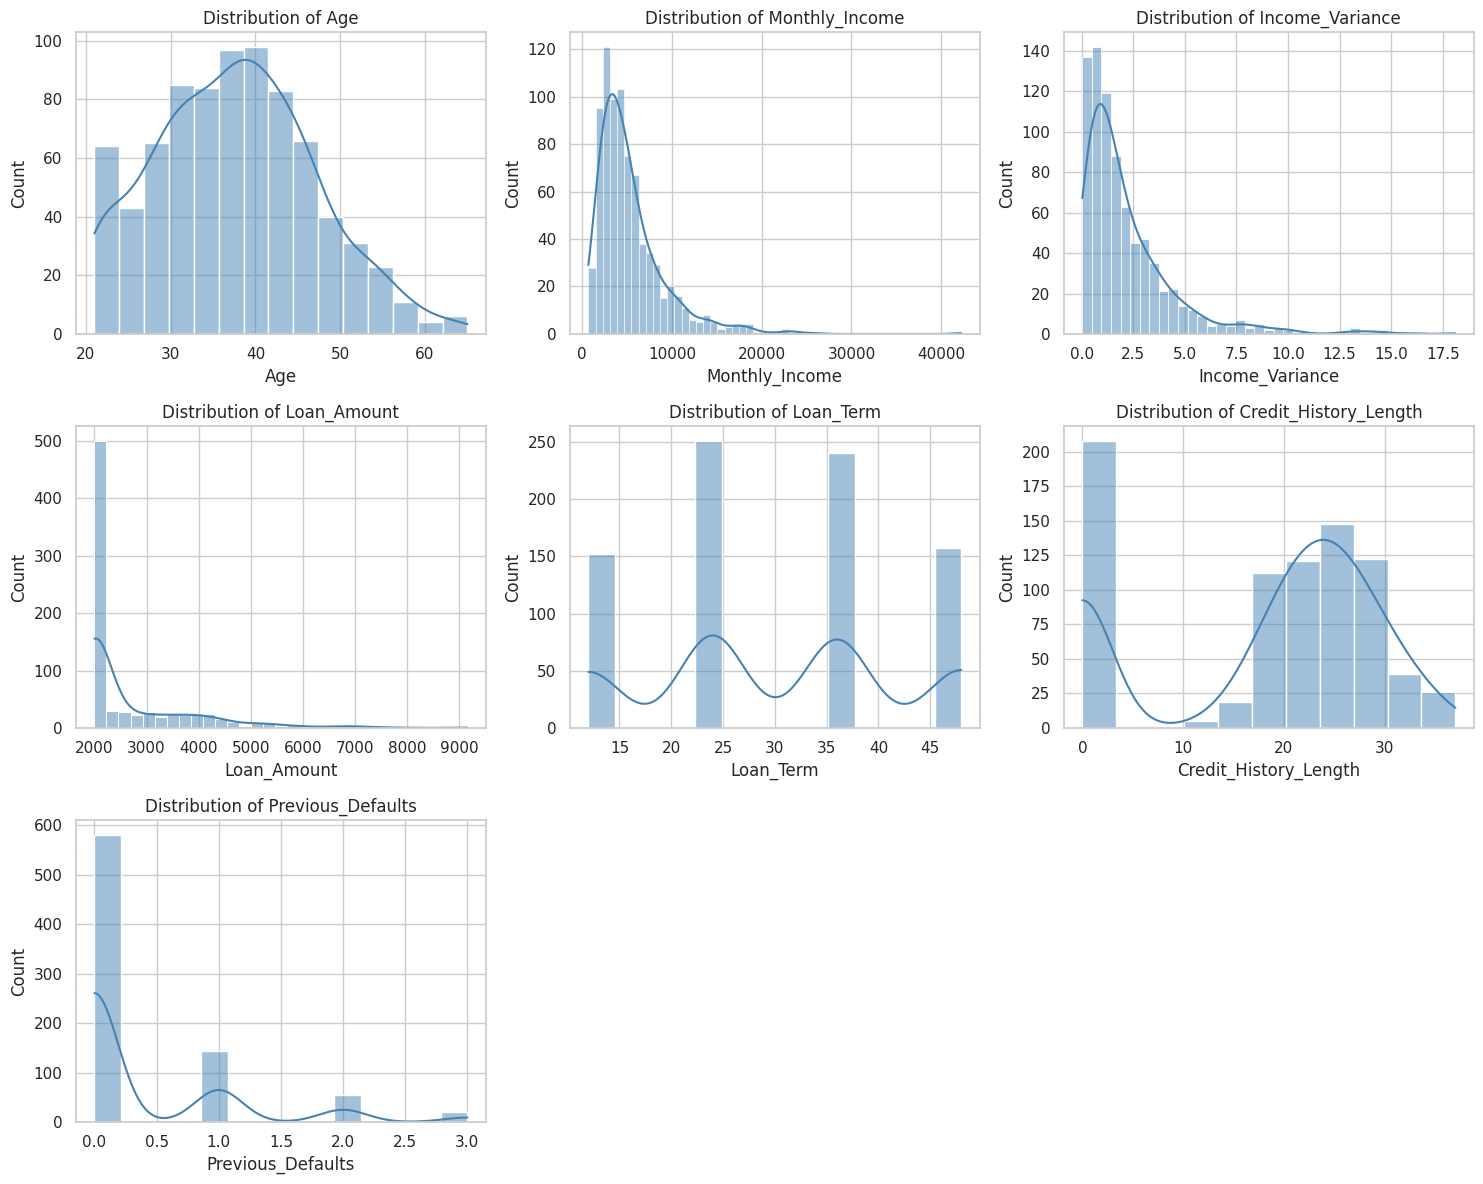

In [ ]:
# Select predictor variables
predictors = df.drop(columns=["Default"])

# Create distribution plots
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, column in enumerate(predictors.columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i],
        color="steelblue"
    )
    axes[i].set_title(f"Distribution of {column}")

# Remove unused plots
for j in range(len(predictors.columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The exploratory analysis reveals that most financial variables do not follow symmetric, bell-shaped distributions. Monthly Income, Income Variance and Loan Amount exhibit substantial positive skewness, while Credit History Length and Previous Defaults have concentrations at zero.

These findings suggest that the dataset contains heterogeneous borrower characteristics and potentially complex financial patterns.

However, non-normal predictor distributions do not automatically violate the assumptions of Logistic Regression, since Logistic Regression does not require normally distributed predictors.

The findings instead provide a reason to investigate whether the relationships between continuous predictors and the log-odds of default are adequately represented by a linear functional form.

A non-parametric model such as Random Forest may be useful if the data contains non-linear relationships or interactions that are not adequately captured by the initial Logistic Regression model. This will need to be established through further diagnostic testing and model comparison.

# Measure skewness
Since we have visually identified skewness. Let's now quantify it using the skewness coefficient.

In [ ]:
# Calculate skewness for each predictor variable
skewness = df.drop(columns=["Default"]).skew()

# Display skewness values
print("Skewness of Predictor Variables:")
print(skewness.sort_values(ascending=False).round(3))

Skewness of Predictor Variables:
Income_Variance          2.646
Monthly_Income           2.636
Loan_Amount              2.087
Previous_Defaults        1.905
Age                      0.256
Loan_Term                0.011
Credit_History_Length   -0.655
dtype: float64


The results show that Income Variance (2.646), Monthly Income (2.636), and Loan Amount (2.087) are highly positively skewed.

Confirming our earlier observations that most applicants have relatively low values for these variables, while a smaller number have considerably higher values.

Previous Defaults (1.905) is also positively skewed, which is expected given that most applicants have no previous defaults, while relatively few have one or more.

Credit History Length (-0.655) is moderately negatively skewed. This suggests an overall longer left tail, influenced by the substantial number of applicants with zero months of credit history. However, its distribution is not simply left-skewed; the earlier histogram also revealed a distinct concentration at zero.

On the other hand, Age (0.256) and Loan Term (0.011) have skewness coefficients close to zero, indicating relatively balanced distributions. However, Loan Term is a discrete variable with specific repayment durations, so its low skewness does not imply that it follows a normal distribution.

*Implications for Model Selection*

The high skewness observed in several financial variables indicates that their distributions are far from symmetric. This may also indicate the presence of extreme observations that could influence parameter estimation.

However, Logistic Regression does not require predictors to be normally distributed. Therefore, skewness alone is insufficient justification for rejecting the parametric model.

We will need to investigate whether the skewed variables have approximately linear relationships with the log-odds of default and whether any extreme observations exert excessive influence on the fitted model.

A Random Forest classifier may provide a useful alternative because it can model non-linear relationships and is less sensitive to extreme predictor magnitudes than some parametric modeling approaches.

 # Identify potential outliers
Let's examine whether the highly skewed variables also contain unusually extreme observations.

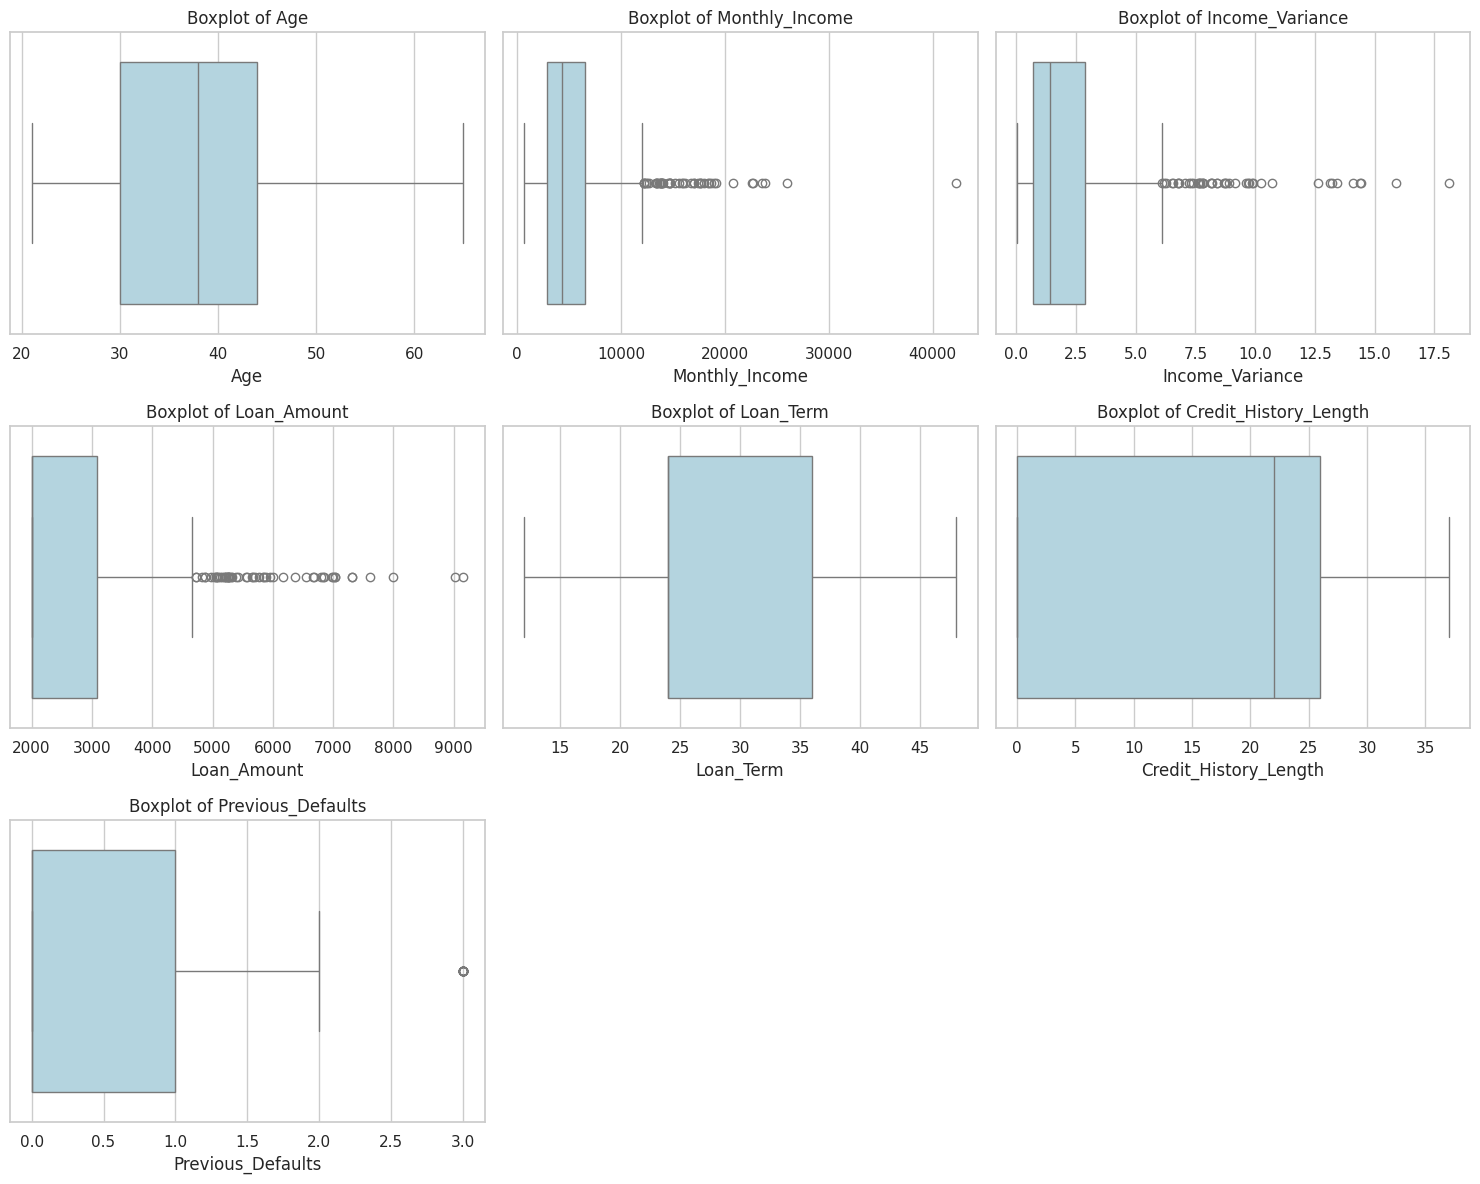

In [ ]:
# Select the predictor variables
predictors = df.drop(columns=["Default"])

# Create boxplots to identify potential outliers
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, column in enumerate(predictors.columns):

    sns.boxplot(
        x=df[column],
        ax=axes[i],
        color="lightblue"
    )

    axes[i].set_title(f"Boxplot of {column}")

# Remove unused subplots
for j in range(len(predictors.columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
# Identify potential outliers using the IQR method
outlier_results = []

for column in predictors.columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_results.append({
        "Variable": column,
        "Potential Outliers": outlier_count,
        "Percentage": round(outlier_count / len(df) * 100, 2)
    })

# Display results in a table
outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Variable,Potential Outliers,Percentage
0,Age,0,0.00
1,Monthly_Income,48,6.00
2,Income_Variance,45,5.62
3,Loan_Amount,55,6.88
4,Loan_Term,0,0.00
5,Credit_History_Length,0,0.00
6,Previous_Defaults,20,2.50


The presence of extreme financial values raises questions about their potential influence on model estimation. In Logistic Regression, observations with unusual predictor values may have high leverage, although not every extreme observation will necessarily exert excessive influence on the fitted coefficients.

Random Forest may be less sensitive to extreme predictor magnitudes because it partitions observations using decision-tree splits rather than fitting a single linear predictor.

The outliers identified here are not sufficient evidence to reject Logistic Regression. Further diagnostic testing, particularly leverage and influence analysis, will be necessary.

At this stage, I will retain all observations because there is no evidence that the extreme values are data entry errors. Their influence on model performance will be investigated during assumption diagnostics.

# Relationship between predictors and loan default

We now need to determine whether the financial characteristics we have examined are associated with actual loan defaults.

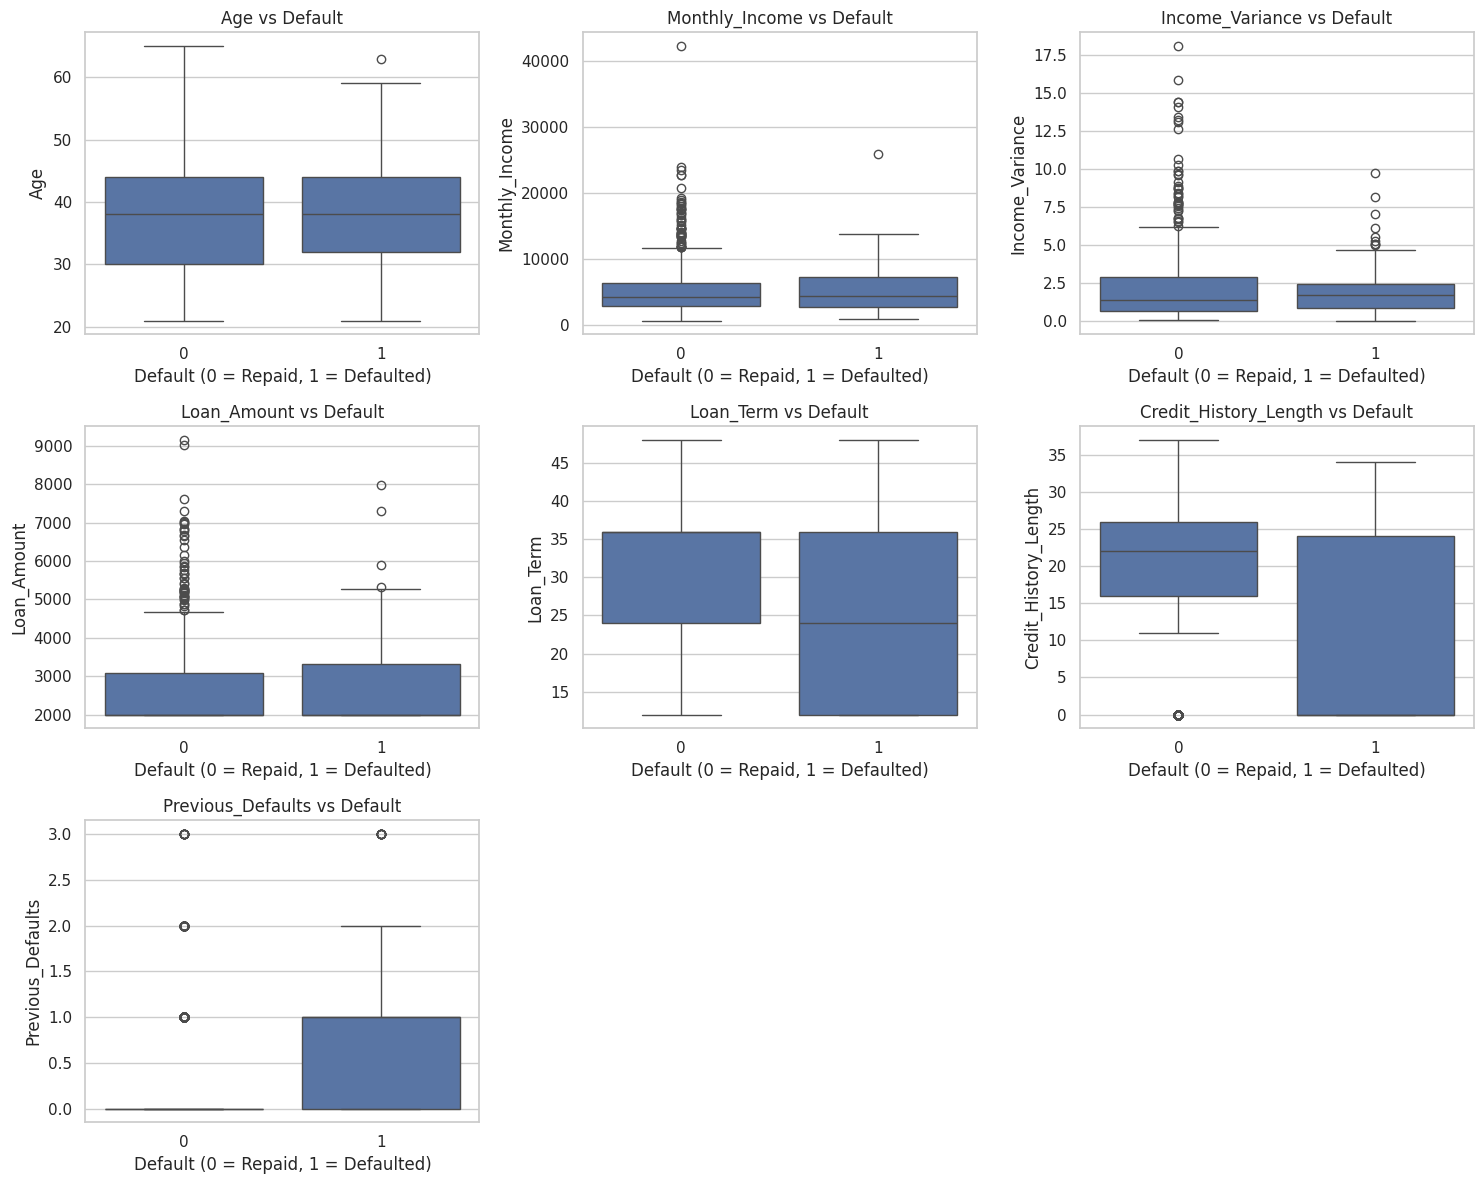

In [ ]:
# Compare predictor distributions between borrowers
# who repaid (0) and those who defaulted (1)

predictors = df.drop(columns=["Default"])

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, column in enumerate(predictors.columns):

    sns.boxplot(
        data=df,
        x="Default",
        y=column,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} vs Default")
    axes[i].set_xlabel("Default (0 = Repaid, 1 = Defaulted)")
    axes[i].set_ylabel(column)

# Remove unused subplots
for j in range(len(predictors.columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
# Calculate average predictor values for each loan outcome
group_comparison = df.groupby("Default")[predictors.columns].mean()

# Transpose for easier comparison
display(group_comparison.T.round(2))

Default,0,1
Age,37.43,38.57
Monthly_Income,5390.11,5335.26
Income_Variance,2.18,2.11
Loan_Amount,2690.19,2682.96
Loan_Term,30.26,28.00
Credit_History_Length,18.78,11.47
Previous_Defaults,0.34,0.90




**Age:** Applicants who defaulted had a slightly higher average age (38.57 years) compared to those who repaid their loans (37.43 years). However, the distributions overlap considerably, suggesting that age alone may not strongly distinguish between the two groups.

**Monthly Income:** The average monthly income was 5,390.11 for applicants who repaid their loans and 5,335.26 for those who defaulted. The difference is relatively small, and both groups have substantial variation in their income levels. This suggests that monthly income alone may have limited ability to distinguish defaulters from non-defaulters.

**Income Variance:** Interestingly, applicants who defaulted had a slightly lower average income variance (2.11) than those who repaid (2.18). This is contrary to what we might initially expect, given the case study's emphasis on irregular income. However, this difference is small, and we cannot conclude from these descriptive statistics that income variability reduces default risk.

**Loan Amount:** The average loan amounts were also nearly identical, at 2,690.19 for repaid loans and 2,682.96 for defaulted loans. The boxplots show considerable overlap, indicating that loan amount alone does not clearly separate the two groups.

**Loan Term:** Applicants who defaulted had a shorter average loan term (28 months) compared to those who repaid (30.26 months). However, the distributions overlap considerably, and further analysis would be needed to establish whether this difference is statistically meaningful.

**Credit History Length:** This variable shows a more noticeable difference. Applicants who repaid their loans had an average credit history of 18.78 months, compared to 11.47 months among those who defaulted.

The boxplots also show a larger concentration of applicants with zero credit history in the default group. This suggests that a shorter or nonexistent borrowing history may be associated with a higher likelihood of default.

**Previous Defaults:** This variable shows another important difference. Applicants who defaulted had an average of 0.90 previous defaults, compared to 0.34 among those who repaid their loans. This suggests that borrowers with a history of default may be more likely to default again.

From these results, Credit History Length and Previous Defaults appear to be the strongest candidate predictors of loan default among the variables examined.

These are descriptive associations rather than confirmed independent effects. We still need to establish how these variables behave when considered together in a predictive model.

The considerable overlap between the two loan outcome groups also indicates that predicting default may not be straightforward.

These findings support further investigation using Logistic Regression and Random Forest to determine whether a relatively simple parametric model can adequately represent the relationships or whether additional flexibility improves predictive performance.

# Investigate potential non-linear relationships
  
We will examine how observed default rates change across different values of continuous predictors.

This may reveal patterns that the previous boxplots could not show.

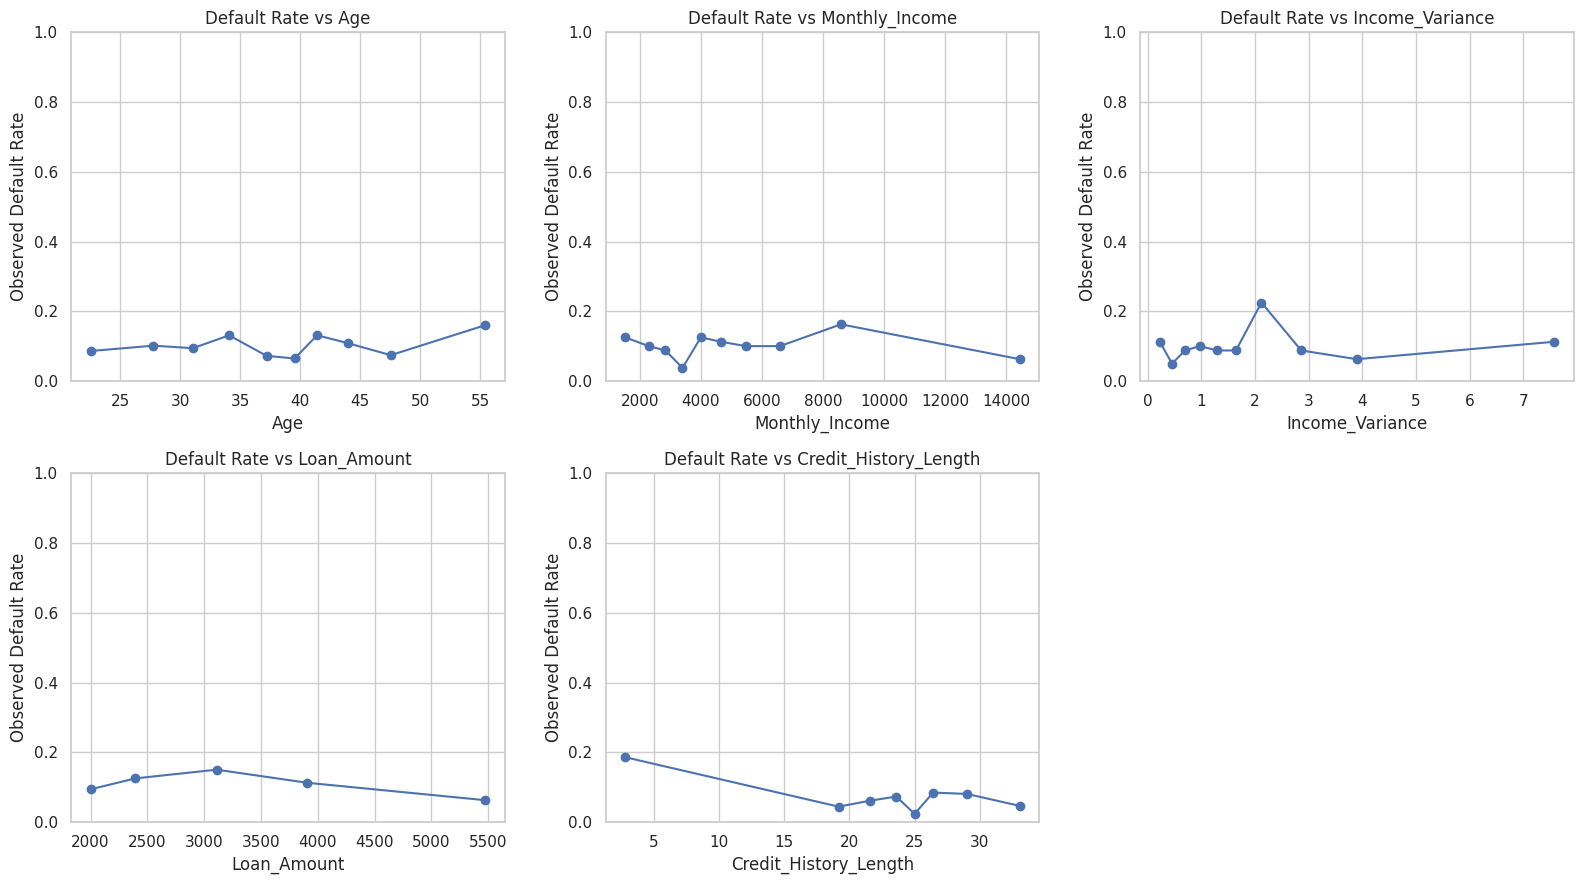

In [ ]:
# Select continuous predictor variables
continuous_features = [
    "Age",
    "Monthly_Income",
    "Income_Variance",
    "Loan_Amount",
    "Credit_History_Length"
]

# Create plots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(continuous_features):

    # Divide observations into quantile-based groups
    bins = pd.qcut(df[column], q=10, duplicates="drop")

    # Calculate mean predictor value and default rate for each group
    summary = df.groupby(bins, observed=True).agg(
        predictor_mean=(column, "mean"),
        default_rate=("Default", "mean"),
        sample_size=("Default", "size")
    )

    # Plot observed default rates
    axes[i].plot(
        summary["predictor_mean"],
        summary["default_rate"],
        marker="o"
    )

    axes[i].set_title(f"Default Rate vs {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Observed Default Rate")

    axes[i].set_ylim(0, 1)

# Remove unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

The plots reveal several irregular and potentially non-linear relationships between the predictor variables and loan default.

Credit History Length shows the most noticeable pattern, while Monthly Income, Income Variance, Age, and Loan Amount exhibit fluctuations without clear monotonic trends.

These findings provide a reason to investigate whether a simple Logistic Regression model adequately captures the relationships.

A Random Forest classifier may offer greater flexibility in representing thresholds, non-linear patterns, and interactions between predictors.

# Task 2: Parametric Model :  Logistic Regression

For the parametric approach, I selected Logistic Regression because our target variable, `Default`, is binary, where 1 represents a loan default and 0 represents repayment.

Logistic Regression estimates the probability of an applicant defaulting based on their demographic, income, and borrowing characteristics.

One reason for selecting this model is its interpretability.

Unlike more complex models, Logistic Regression allows us to examine how individual predictor variables are associated with the odds of loan default while holding other predictors constant.

It will also serve as our baseline model, against which we will compare the non-parametric Random Forest classifier.

Although our exploratory analysis revealed skewness, outliers, and potential non-linear relationships, these findings alone do not invalidate Logistic Regression.

We will therefore fit the model and subsequently test its assumptions before determining whether it is suitable for this credit risk prediction problem.


The Logistic Regression model is expressed as:
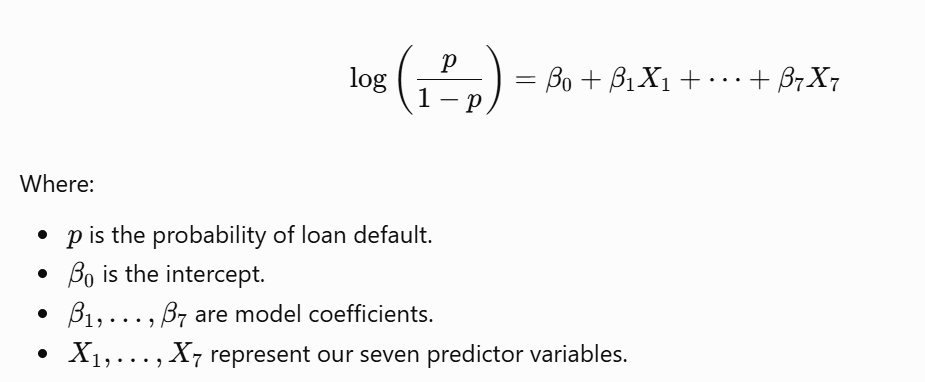






In [ ]:
# Separate independent variables (predictors) from the target variable

X = df.drop(columns=["Default"])

# Target variable: 1 = Defaulted, 0 = Repaid
y = df["Default"]

# Verify the dimensions
print("Predictor variables:", X.shape)
print("Target variable:", y.shape)

# Display predictor names
print("\nPredictors:")
print(X.columns.tolist())

Predictor variables: (800, 7)
Target variable: (800,)

Predictors:
['Age', 'Monthly_Income', 'Income_Variance', 'Loan_Amount', 'Loan_Term', 'Credit_History_Length', 'Previous_Defaults']


# Split the data into training and testing sets

We will use an 80/20 stratified train-test split.


Stratification is chosen because only approximately 10% of applicants defaulted.

It  will help us maintain similar default proportions in both subsets.

In [ ]:
from sklearn.model_selection import train_test_split

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (640, 7)
Testing features: (160, 7)

Training target distribution:
Default
0    0.898
1    0.102
Name: proportion, dtype: float64

Testing target distribution:
Default
0    0.9
1    0.1
Name: proportion, dtype: float64


# Standardize predictor variables

Our predictors have very different measurement scales. For example, Monthly Income can exceed 40,000, while Previous Defaults ranges from 0 to 3.
We will standardize the predictors to improve numerical optimization and make regularization operate more consistently across variables.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to testing data
X_test_scaled = scaler.transform(X_test)

# Convert scaled data back into DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Preview standardized training data
X_train_scaled.head()

,Age,Monthly_Income,Income_Variance,Loan_Amount,Loan_Term,Credit_History_Length,Previous_Defaults
326,1.219178,-0.120417,-0.335550,2.241514,0.476957,-0.015574,-0.535380
40,0.792215,-0.366985,-0.693433,-0.519030,-0.510915,-1.603262,-0.535380
436,1.752881,1.539421,0.955817,-0.330617,-1.498787,0.954681,2.261708
314,1.432659,-0.233428,0.823344,-0.579794,-0.510915,-1.603262,0.863164
461,0.045031,-0.285030,-0.189845,-0.579794,-0.510915,0.249041,-0.535380


# Train the Logistic Regression model

For interpretable statistical coefficients and odds ratios, we will use statsmodels to fit an unpenalized Logistic Regression model using maximum likelihood estimation.

In [ ]:
import statsmodels.api as sm

# Add an intercept to the predictor matrix
X_train_sm = sm.add_constant(
    X_train_scaled,
    has_constant="add"
)

# Initialize Logistic Regression
logit_model = sm.Logit(y_train, X_train_sm)

# Fit the model using maximum likelihood estimation
logit_results = logit_model.fit(maxiter=200)

# Display model summary
print(logit_results.summary())

Optimization terminated successfully.
         Current function value: 0.286122
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                Default   No. Observations:                  640
Model:                          Logit   Df Residuals:                      632
Method:                           MLE   Df Model:                            7
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                  0.1290
Time:                        14:39:28   Log-Likelihood:                -183.12
converged:                       True   LL-Null:                       -210.24
Covariance Type:            nonrobust   LLR p-value:                 2.101e-09
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -2.5061      0.165    -15.206      0.000      -2.829      -2.

The model above converged successfully after seven iterations, indicating that the optimization procedure found a solution without reporting convergence problems.

The likelihood ratio test produced a p-value of approximately 2.101 × 10⁻⁹, which is statistically significant at the 5% level. This suggests that the model containing the predictors provides a better fit than an intercept-only model.

The model also produced a McFadden's Pseudo R-squared value of 0.129. Unlike the R-squared used in linear regression, this value does not mean that the model explains 12.9% of the variation in loan defaults. Rather, it reflects an improvement in log-likelihood relative to the intercept-only model.

I would say the model provides evidence that some of the predictors are associated with loan default.

In [ ]:
# Extract estimated coefficients
coefficients = logit_results.params

# Convert coefficients to odds ratios
odds_ratios = np.exp(coefficients)

# Create a summary table
coefficient_summary = pd.DataFrame({
    "Coefficient": coefficients,
    "Odds Ratio": odds_ratios,
    "P-value": logit_results.pvalues
})

# Display results
display(coefficient_summary.round(4))

,Coefficient,Odds Ratio,P-value
const,-2.5061,0.0816,0.0000
Age,0.1100,1.1162,0.4123
Monthly_Income,-0.0248,0.9755,0.9106
Income_Variance,-0.0461,0.9549,0.8247
Loan_Amount,0.0356,1.0362,0.8172
Loan_Term,-0.2945,0.7449,0.0348
Credit_History_Length,-0.5476,0.5783,0.0000
Previous_Defaults,0.6106,1.8415,0.0000


I examined the estimated coefficients, odds ratios, and p-values  as above to understand the direction and magnitude of each predictor's association with loan default.

**Loan Term:** The coefficient is -0.2945, with an odds ratio of 0.7449 and a p-value of 0.0348. This indicates that a one-standard-deviation increase in loan term is associated with approximately 25.5% lower odds of default, holding the other predictors constant. The relationship is statistically significant at the 5% level.

**Credit History Length:** The coefficient is -0.5476, with an odds ratio of 0.5783 and a p-value below 0.001. This indicates that a one-standard-deviation increase in credit history length is associated with approximately 42.2% lower odds of default, holding other predictors constant.

**Previous Defaults:** The coefficient is 0.6106, with an odds ratio of 1.8415 and a p-value below 0.001. This suggests that a one-standard-deviation increase in previous defaults is associated with approximately 84.2% higher odds of default.

These findings are consistent with the earlier exploratory analysis, where applicants who defaulted generally had shorter credit histories and more previous defaults.

Age, Monthly Income, Income Variance, and Loan Amount were not statistically significant at the 5% level. Their estimated coefficients were relatively small, and their p-values exceeded 0.05.

Income Variance was not statistically significant despite the case study's emphasis on irregular income. This suggests that income variability does not show a clear independent linear association with the log-odds of default in the fitted model.

I conclude that Credit History Length, Previous Defaults, and Loan Term are the statistically significant predictors in this initial model.

Accuracy: 0.8938
Precision: 0.4
Recall: 0.125
F1-score: 0.1905
ROC-AUC: 0.701
PR-AUC (Average Precision): 0.2692

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.94       144
           1       0.40      0.12      0.19        16

    accuracy                           0.89       160
   macro avg       0.65      0.55      0.57       160
weighted avg       0.86      0.89      0.87       160



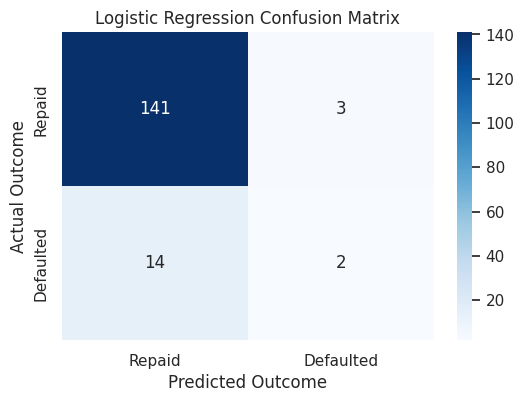

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Prepare test predictors with an intercept
X_test_sm = sm.add_constant(
    X_test_scaled,
    has_constant="add"
)

# Predict probability of default
y_prob = logit_results.predict(X_test_sm)

# Convert probabilities into binary predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC (Average Precision):",
      round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Repaid", "Defaulted"],
    yticklabels=["Repaid", "Defaulted"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.show()

The Logistic Regression model  is evaluated on the test dataset containing 160 observations, including 16 actual defaults and 144 repaid loans.

The model achieved an accuracy of 89.38%. At first glance, this appears to indicate strong predictive performance. However, the classification report and confusion matrix reveal a different picture as seen.

The model correctly identified 141 applicants who repaid their loans but identified only 2 of the 16 applicants who defaulted. It incorrectly classified 14 defaulters as non-defaulters.

The recall for the default class was therefore only 12.5%, indicating that the model missed 87.5% of actual defaults. Precision was 40%, meaning that only 2 out of the 5 applicants predicted to default actually defaulted.

The F1-score for the default class was 0.1905, indicating poor performance in balancing precision and recall.

The model achieved a ROC-AUC of 0.701, suggesting some ability to distinguish between defaulters and non-defaulters across different classification thresholds.

The PR-AUC, measured using Average Precision, was 0.2692. Although this exceeds the default prevalence of 10% in the test data, it still indicates limitations in identifying the minority class.

The high overall accuracy is misleading because approximately 90% of applicants repaid their loans. In fact, a model that predicted repayment for every applicant would achieve 90% accuracy on this test set, slightly higher than our Logistic Regression model.

For a microfinance institution, this performance raises serious concerns because failing to identify applicants who are likely to default may expose the institution to financial losses.

These results do not necessarily mean Logistic Regression is unsuitable. The current model uses a classification threshold of 0.5, which may not be appropriate for an imbalanced credit risk dataset.

I will conduct further evaluation of classification thresholds, assumption diagnostics, and comparison with a non-parametric model before making a final recommendation.

# Task 3: Assumption Diagnostics

Our Logistic Regression model achieved 89.38% accuracy but only 12.5% recall for loan defaults.
We now need to investigate whether the model's limitations are related to violated statistical assumptions, class imbalance, or other factors.

 ## Check linearity in the log-odds

Logistic Regression assumes that continuous predictors enter the model through an appropriate functional form.

In our initial model, we assumed a linear relationship between each continuous predictor and the log-odds of default.

This does not mean the relationship between a predictor and the probability of default must be linear.

So to test this out, we will first use a visual diagnostic, followed by a more formal comparison against a model that permits non-linear effects.

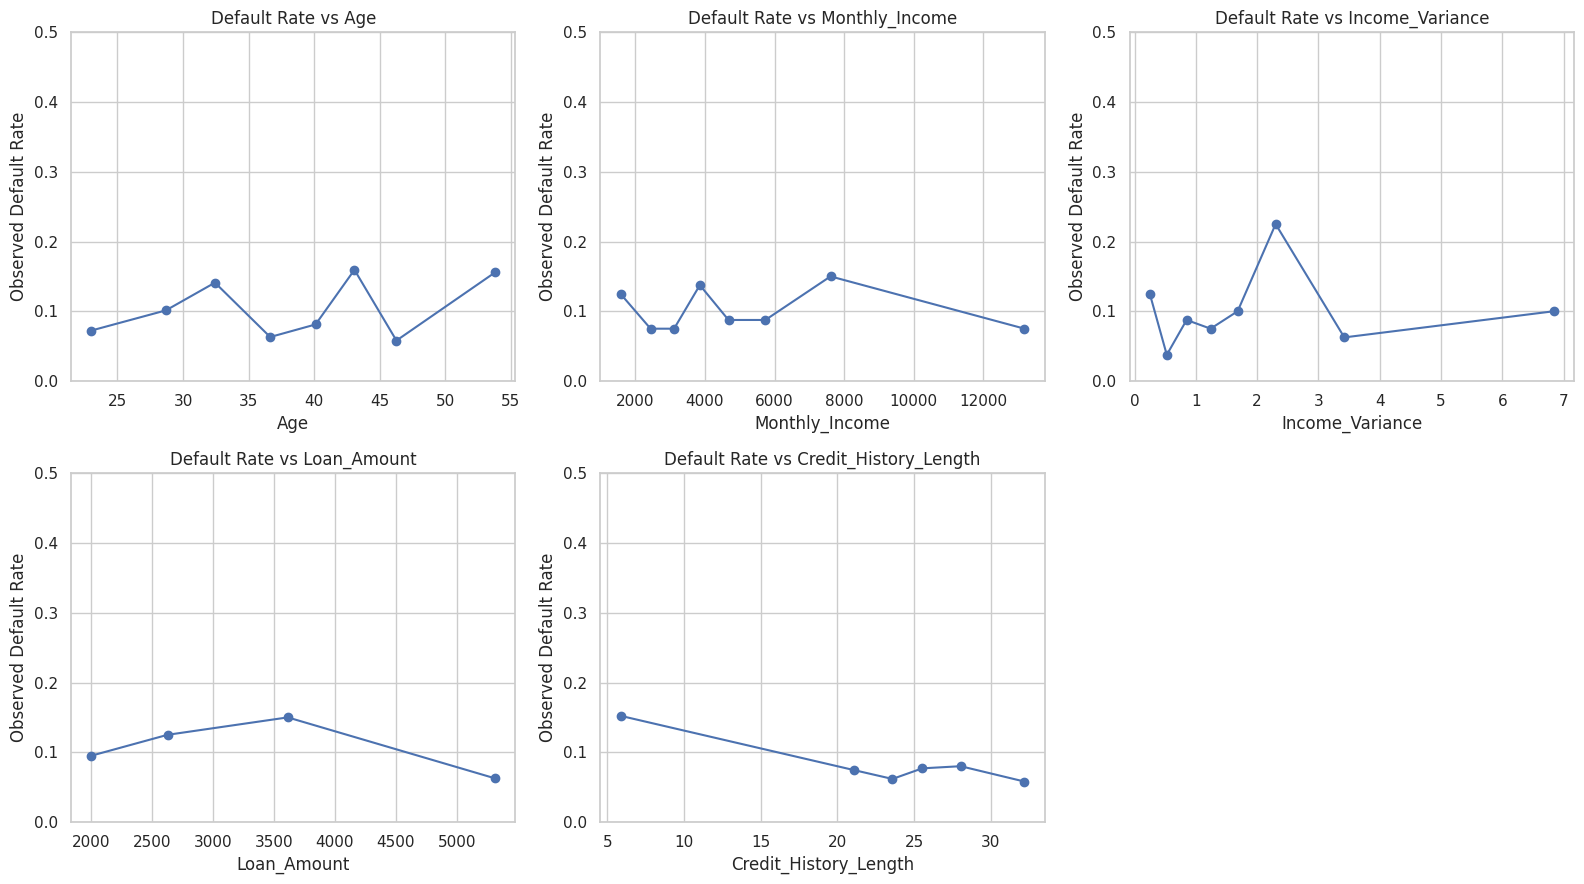

In [ ]:
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Continuous predictors to investigate
continuous_features = [
    "Age",
    "Monthly_Income",
    "Income_Variance",
    "Loan_Amount",
    "Credit_History_Length"
]

# Plot binned default rates against each continuous variable
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(continuous_features):

    # Group observations into quantile-based bins
    bins = pd.qcut(
        X_train[column],
        q=8,
        duplicates="drop"
    )

    # Calculate default rate in each bin
    summary = pd.DataFrame({
        "Value": X_train[column],
        "Default": y_train,
        "Bin": bins
    }).groupby("Bin", observed=True).agg(
        Mean_Value=("Value", "mean"),
        Default_Rate=("Default", "mean"),
        Count=("Default", "size")
    )

    axes[i].plot(
        summary["Mean_Value"],
        summary["Default_Rate"],
        marker="o"
    )

    axes[i].set_title(f"Default Rate vs {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Observed Default Rate")
    axes[i].set_ylim(0, 0.5)

# Remove unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

The plots show fluctuations in default rates across the continuous predictors. Loan Amount and Income Variance exhibit possible non-linear patterns, while Credit History Length shows a more consistent decline in default risk as borrowing history increases.

## Test linearity using a more flexible model

For a more rigorous assessment, we'll compare our original Logistic Regression model against an alternative Logistic Regression model that uses cubic splines.

Splines allow curved relationships while keeping the model within the logistic regression framework.

We'll use a likelihood ratio test to investigate whether allowing non-linear effects significantly improves model fit.

In [ ]:
from patsy import dmatrix
from scipy.stats import chi2

# Create a copy of the standardized training predictors
X_spline = X_train_scaled.copy()

# Replace each continuous linear predictor with spline terms
for column in continuous_features:

    spline_terms = dmatrix(
        "bs(x, df=4, degree=3, include_intercept=False) - 1",
        {"x": X_train_scaled[column]},
        return_type="dataframe"
    )

    # Preserve the training index
    spline_terms.index = X_train_scaled.index

    # Assign unique column names
    spline_terms.columns = [
        f"{column}_spline_{i}"
        for i in range(spline_terms.shape[1])
    ]

    # Remove original linear term
    X_spline = X_spline.drop(columns=[column])

    # Add flexible spline terms
    X_spline = pd.concat(
        [X_spline, spline_terms],
        axis=1
    )

# Add intercept
X_spline = sm.add_constant(
    X_spline,
    has_constant="add"
)

# Fit the flexible logistic regression model
spline_model = sm.Logit(y_train, X_spline).fit(
    maxiter=300
)

# Compare log-likelihoods
lr_statistic = 2 * (
    spline_model.llf - logit_results.llf
)

# Difference in number of estimated parameters
df_difference = (
    len(spline_model.params) -
    len(logit_results.params)
)

# Calculate p-value
p_value = chi2.sf(lr_statistic, df_difference)

print("Linearity Assessment")
print("--------------------")
print("Original model LL:", round(logit_results.llf, 3))
print("Spline model LL:", round(spline_model.llf, 3))
print("Likelihood Ratio Statistic:", round(lr_statistic, 3))
print("Degrees of Freedom:", df_difference)
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print(
        "\nEvidence of improvement from allowing nonlinear effects."
    )
else:
    print(
        "\nNo statistically significant improvement detected."
    )

Optimization terminated successfully.
         Current function value: 0.277500
         Iterations 11
Linearity Assessment
--------------------
Original model LL: -183.118
Spline model LL: -177.6
Likelihood Ratio Statistic: 11.036
Degrees of Freedom: 15
P-value: 0.75

No statistically significant improvement detected.


The likelihood ratio test produced a statistic of 11.036 with 15 degrees of freedom and a p-value of 0.75.

Since the p-value exceeds 0.05, allowing non-linear spline terms did not significantly improve model fit compared to the original Logistic Regression model.

Therefore, there is insufficient statistical evidence to reject the original linear functional form.

However, this does not prove that the linearity assumption is fully satisfied.

## Test multicollinearity using VIF
Multicollinearity occurs when predictor variables are strongly linearly related to one another.

For example, we might suspect that Monthly Income and Loan Amount are related, since applicants with higher incomes may request larger loans.

High multicollinearity can make Logistic Regression coefficient estimates unstable and their individual effects difficult to interpret.

We want to establish whether relationships among the predictors may be distorting coefficient estimates or increasing their standard errors.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Use the standardized training predictors with intercept
X_vif = sm.add_constant(
    X_train_scaled,
    has_constant="add"
)

# Calculate VIF for each predictor
vif_results = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Exclude the intercept from interpretation
vif_results = vif_results[
    vif_results["Variable"] != "const"
]

display(vif_results.sort_values(
    by="VIF",
    ascending=False
).round(3))

,Variable,VIF
2,Monthly_Income,2.175
3,Income_Variance,1.888
4,Loan_Amount,1.195
6,Credit_History_Length,1.017
1,Age,1.007
7,Previous_Defaults,1.006
5,Loan_Term,1.003


The VIF results range from 1.003 to 2.175. Monthly Income has the highest VIF (2.175), followed by Income Variance (1.888).

Since all VIF values are below 5, there is no evidence of problematic linear multicollinearity among the predictors. This suggests that multicollinearity is unlikely to be substantially destabilizing the Logistic Regression coefficient estimates.

## Investigate influential observations and outliers
Earlier we identified potential outliers in Monthly Income, Income Variance, Loan Amount, and Previous Defaults.

However, an extreme predictor value is not necessarily an influential observation.
We need to distinguish between:
- Outliers: Observations with unusual values.
- Leverage: Observations with unusual combinations of predictor values.
- Influence: Observations that substantially affect estimated model coefficients.

We'll examine leverage and Cook's distance.

In [ ]:
# Obtain influence diagnostics from the fitted Logistic Regression
influence = logit_results.get_influence()

# Extract influence statistics
influence_summary = influence.summary_frame()

# View available diagnostic columns
print(influence_summary.columns.tolist())

# Examine Cook's distance and leverage
diagnostics = influence_summary[[
    "cooks_d",
    "hat_diag"
]].copy()

# Calculate conventional screening thresholds
n = len(X_train)
p = len(logit_results.params)

cooks_threshold = 4 / n
leverage_threshold = 2 * p / n

print("Cook's Distance Threshold:", round(cooks_threshold, 4))
print("Leverage Threshold:", round(leverage_threshold, 4))

# Count observations exceeding thresholds
print(
    "Potentially influential observations:",
    (diagnostics["cooks_d"] > cooks_threshold).sum()
)

print(
    "High-leverage observations:",
    (diagnostics["hat_diag"] > leverage_threshold).sum()
)

# Display observations with highest Cook's distance
display(
    diagnostics.sort_values(
        "cooks_d",
        ascending=False
    ).head(10)
)

['dfb_const', 'dfb_Age', 'dfb_Monthly_Income', 'dfb_Income_Variance', 'dfb_Loan_Amount', 'dfb_Loan_Term', 'dfb_Credit_History_Length', 'dfb_Previous_Defaults', 'cooks_d', 'standard_resid', 'hat_diag', 'dffits_internal']
Cook's Distance Threshold: 0.0063
Leverage Threshold: 0.025
Potentially influential observations: 55
High-leverage observations: 73


,cooks_d,hat_diag
85,0.038555,0.082647
214,0.035295,0.022436
618,0.033761,0.132309
626,0.031127,0.043424
466,0.026909,0.007415
598,0.023974,0.010249
244,0.023554,0.021661
762,0.023236,0.013811
266,0.020977,0.019221
366,0.019990,0.117277


Using Cook's distance and leverage diagnostics, I identified 55 observations exceeding the Cook's distance screening threshold of 0.0063 and 73 observations exceeding the leverage threshold of 0.025.

The highest Cook's distance was approximately 0.0386, suggesting that some observations may have a greater influence on model estimation than others.

Although several observations exceeded the screening thresholds, their values do not automatically indicate serious model instability. Further sensitivity analysis would be required to establish whether excluding these observations materially changes the estimated coefficients.

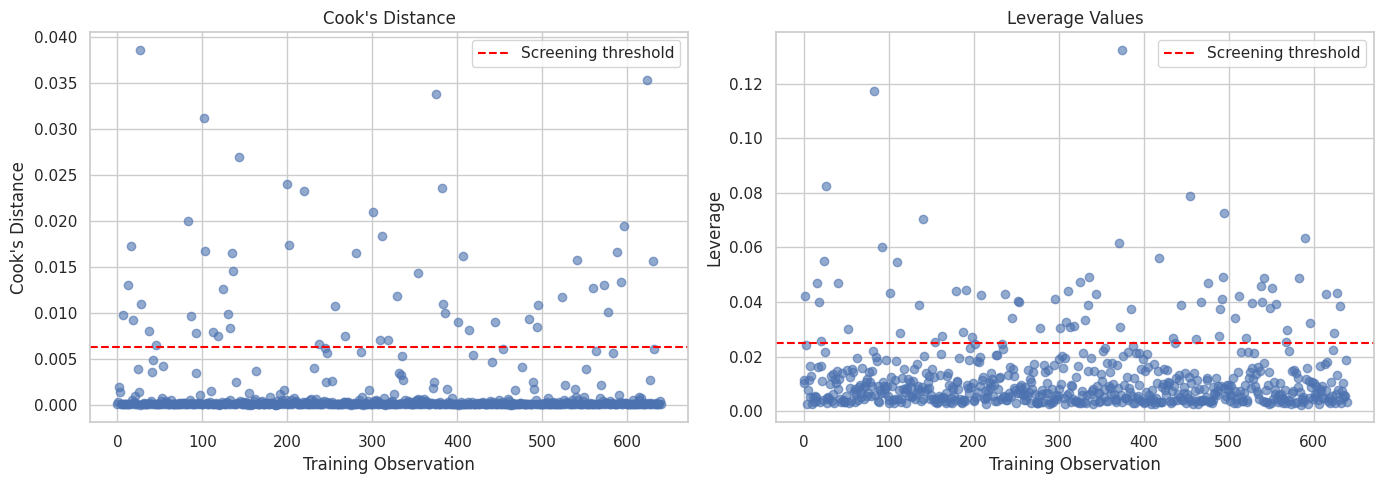

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cook's distance
axes[0].scatter(
    range(len(diagnostics)),
    diagnostics["cooks_d"],
    alpha=0.6
)

axes[0].axhline(
    cooks_threshold,
    color="red",
    linestyle="--",
    label="Screening threshold"
)

axes[0].set_title("Cook's Distance")
axes[0].set_xlabel("Training Observation")
axes[0].set_ylabel("Cook's Distance")
axes[0].legend()

# Leverage
axes[1].scatter(
    range(len(diagnostics)),
    diagnostics["hat_diag"],
    alpha=0.6
)

axes[1].axhline(
    leverage_threshold,
    color="red",
    linestyle="--",
    label="Screening threshold"
)

axes[1].set_title("Leverage Values")
axes[1].set_xlabel("Training Observation")
axes[1].set_ylabel("Leverage")
axes[1].legend()

plt.tight_layout()
plt.show()

The plots show that most observations have relatively low Cook's distance and leverage values, while a smaller number exceed the screening thresholds.

This confirms that some observations warrant closer investigation. However, there is currently insufficient evidence to conclude that these observations fundamentally compromise the model. I will retain them unless further analysis establishes that they are erroneous or excessively influential.

## Investigate class imbalance and separation
We already established that only about 10% of applicants defaulted.

Now we'll examine two related but different questions.

Class imbalance: Are there substantially fewer defaults than repayments?
Class separation: Do predictor values perfectly or nearly perfectly distinguish defaulters from non-defaulters?

In [ ]:
# Count observations by outcome
class_counts = y_train.value_counts().sort_index()

# Calculate percentages
class_percentages = (
    y_train.value_counts(normalize=True)
    .sort_index() * 100
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_summary.index = ["Repaid (0)", "Defaulted (1)"]

display(class_summary.round(2))

,Count,Percentage
Repaid (0),575,89.84
Defaulted (1),65,10.16


The training dataset contains 575 repaid loans (89.84%) and 65 defaulted loans (10.16%), confirming substantial class imbalance.

This imbalance helps explain why the Logistic Regression model achieved high overall accuracy but performed poorly in identifying defaults. With only 12.5% recall for the default class on the test set, the model missed most actual defaults at the selected classification threshold.

Therefore, accuracy alone is insufficient for evaluating the model's usefulness in credit risk prediction.

,count,mean,std,min,25%,50%,75%,max
Actual_Default,,,,,,,,
0,575.0,0.0903,0.0847,0.0155,0.0377,0.0607,0.1136,0.7532
1,65.0,0.2012,0.1618,0.0326,0.0768,0.1632,0.2733,0.7113


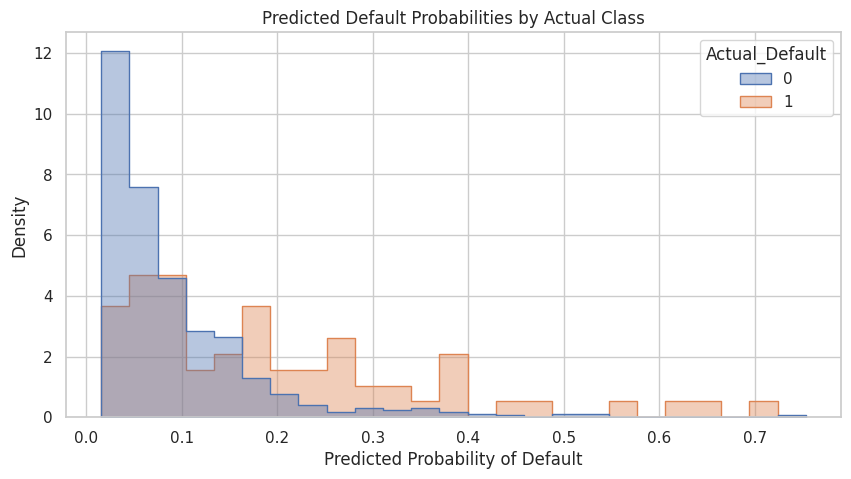

Probabilities near zero: 0
Probabilities near one: 0
Model converged: True


In [ ]:
# Obtain fitted probabilities on training data
train_prob = logit_results.predict(X_train_sm)

# Summarize predicted probabilities by actual outcome
separation_summary = pd.DataFrame({
    "Actual_Default": y_train,
    "Predicted_Probability": train_prob
})

display(
    separation_summary.groupby("Actual_Default")[
        "Predicted_Probability"
    ].describe().round(4)
)

# Plot the probability distributions
plt.figure(figsize=(10, 5))

sns.histplot(
    data=separation_summary,
    x="Predicted_Probability",
    hue="Actual_Default",
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.4
)

plt.title("Predicted Default Probabilities by Actual Class")
plt.xlabel("Predicted Probability of Default")
plt.ylabel("Density")
plt.show()

# Check for extremely fitted probabilities
print(
    "Probabilities near zero:",
    (train_prob < 1e-6).sum()
)

print(
    "Probabilities near one:",
    (train_prob > 1 - 1e-6).sum()
)

print("Model converged:", logit_results.mle_retvals["converged"])

The mean predicted default probability was 0.0903 for borrowers who repaid and 0.2012 for those who defaulted. Although the model assigned higher average probabilities to actual defaulters, the probability distributions overlap considerably.

No predicted probabilities were extremely close to 0 or 1, and the model converged successfully.

These findings do not suggest obvious complete separation. However, the substantial overlap indicates limited ability to distinguish the two classes reliably, and the probability diagnostic alone cannot formally rule out separation.

### Overall Assessment of Parametric Model Assumptions

Based on the diagnostic results, I conclude that **the Logistic Regression assumptions are broadly supported by the tests conducted, although some concerns remain regarding influential observations and class imbalance**.

The formal linearity assessment did not identify a statistically significant improvement from introducing non-linear spline terms (p = 0.750). Multicollinearity was also not a major concern, with all VIF values below 5.

Although several observations exceeded the Cook's distance and leverage screening thresholds, further sensitivity analysis would be needed to establish whether they materially affect model stability.

The model converged successfully, and the predicted probabilities did not suggest obvious complete separation. However, the substantial overlap between the two outcome classes indicates limited classification ability.

Class imbalance remains an important predictive challenge, with only 10.16% of training observations representing defaults.

**there is insufficient evidence to conclude that the parametric assumptions are fundamentally violated**. Logistic Regression therefore remains statistically defensible, although its poor default recall at the 0.5 threshold limits its immediate practical suitability.

The next step is to assess whether alternative models or decision thresholds can improve default detection without introducing excessive false positives.

# Task 4: Evaluation of a Candidate Model for Rejection

For this task, I selected an unpruned Decision Tree Classifier as a candidate model for rejection.

Unlike Logistic Regression, Decision Trees do not assume a linear relationship between predictors and the log-odds of default. They can capture non-linear relationships and interactions by repeatedly partitioning the data based on predictor values.

However, an unrestricted Decision Tree can become excessively complex, fitting patterns and noise that are specific to the training dataset. This may result in high training accuracy but poor generalization to unseen observations.

I will therefore examine its training performance, cross-validation performance, model complexity, and stability before deciding whether it should be rejected in favour of other modeling approaches.



The unpruned Decision Tree was selected for evaluation because, although it can model complex non-linear relationships, its unrestricted structure creates a potential risk of overfitting.

I will compare its training and cross-validation performance, examine the effect of tree depth, and assess its sensitivity to changes in the training observations.

If the results show that the unrestricted model fits the training data substantially better than it generalizes to validation data, this would provide evidence for rejecting it due to high variance and poor generalization.

For a microfinance institution, a model with unstable predictions may be difficult to justify in lending decisions, particularly where consistency, interpretability, and accountability are important.

The final rejection decision will depend on the empirical results rather than the assumption that Decision Trees necessarily overfit.

## Train an unpruned Decision Tree
### Fit the candidate model
We will use the original unscaled training data because Decision Trees do not require standardized predictors.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Initialize an unrestricted Decision Tree
decision_tree = DecisionTreeClassifier(
    random_state=42
)

# Train the model using training data only
decision_tree.fit(X_train, y_train)

# Predict outcomes on the training data
y_train_tree = decision_tree.predict(X_train)

# Evaluate training performance
print("Training Accuracy:",
      round(accuracy_score(y_train, y_train_tree), 4))

print("Training F1-score:",
      round(f1_score(y_train, y_train_tree, zero_division=0), 4))

# Examine tree complexity
print("Tree Depth:", decision_tree.get_depth())
print("Number of Leaf Nodes:", decision_tree.get_n_leaves())

Training Accuracy: 1.0
Training F1-score: 1.0
Tree Depth: 13
Number of Leaf Nodes: 87


The Decision Tree achieved 100% training accuracy and an F1-score of 1.0, with a depth of 13 and 87 leaf nodes. Although this indicates that the model perfectly classified the training observations, its complexity raises concerns about overfitting. We need to examine its performance on unseen data to establish whether it generalizes effectively.

## Evaluate generalization using cross-validation
### Stratified 5-fold cross-validation

We'll use stratified cross-validation to assess whether the Decision Tree generalizes consistently across different validation samples.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate multiple classification metrics
tree_cv = cross_validate(
    decision_tree,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

# Summarize results
cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Mean CV Score": [
        tree_cv["test_accuracy"].mean(),
        tree_cv["test_precision"].mean(),
        tree_cv["test_recall"].mean(),
        tree_cv["test_f1"].mean(),
        tree_cv["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        tree_cv["test_accuracy"].std(),
        tree_cv["test_precision"].std(),
        tree_cv["test_recall"].std(),
        tree_cv["test_f1"].std(),
        tree_cv["test_roc_auc"].std()
    ]
})

display(cv_summary.round(4))

,Metric,Mean CV Score,Standard Deviation
0,Accuracy,0.8141,0.0409
1,Precision,0.1874,0.1193
2,Recall,0.2154,0.1323
3,F1-score,0.1954,0.1165
4,ROC-AUC,0.5486,0.0762


The model's performance declined considerably during 5-fold cross-validation, achieving an average accuracy of 81.41%, recall of 21.54%, F1-score of 0.1954, and ROC-AUC of 0.5486.

The substantial difference between training and cross-validation performance provides evidence of overfitting. The low ROC-AUC also suggests that the model has limited ability to distinguish defaulters from non-defaulters on unseen observations.

## Examine the bias–variance tradeoff
### Compare training and validation performance across tree depths
We will investigate whether restricting tree complexity improves generalization.

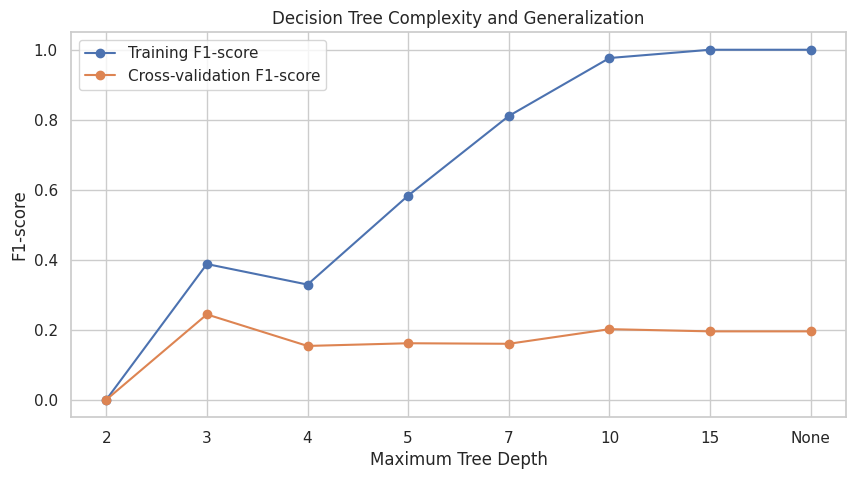

In [ ]:
from sklearn.model_selection import cross_val_score

depths = [2, 3, 4, 5, 7, 10, 15, None]

train_scores = []
validation_scores = []

for depth in depths:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Fit on full training data
    tree.fit(X_train, y_train)

    # Training F1-score
    train_f1 = f1_score(
        y_train,
        tree.predict(X_train),
        zero_division=0
    )

    # Cross-validation F1-score
    cv_f1 = cross_val_score(
        tree,
        X_train,
        y_train,
        cv=cv,
        scoring="f1"
    ).mean()

    train_scores.append(train_f1)
    validation_scores.append(cv_f1)

# Plot the results
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(depths)),
    train_scores,
    marker="o",
    label="Training F1-score"
)

plt.plot(
    range(len(depths)),
    validation_scores,
    marker="o",
    label="Cross-validation F1-score"
)

plt.xticks(
    range(len(depths)),
    [str(d) for d in depths]
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("F1-score")
plt.title("Decision Tree Complexity and Generalization")
plt.legend()
plt.grid(True)
plt.show()

The depth comparison investigates how increasing model complexity affects training and validation performance. The unrestricted tree achieved perfect training performance, while its cross-validation F1-score was only approximately 0.195.

This large generalization gap supports a high-variance interpretation: the tree fits the training observations closely but fails to generalize effectively. Restricting tree depth may help reduce overfitting, although the optimal complexity would require further validation.

## Examine model stability
### Evaluate sensitivity to changes in training data
We will compare the predictions of trees trained on different bootstrap samples. If small changes in training observations produce substantially different predictions, that suggests instability.

In [ ]:
from sklearn.utils import resample
from sklearn.metrics import accuracy_score

# Store predictions from different bootstrap models
bootstrap_predictions = []

for seed in range(30):

    # Draw a bootstrap sample from training data
    X_boot, y_boot = resample(
        X_train,
        y_train,
        replace=True,
        n_samples=len(X_train),
        random_state=seed
    )

    # Fit a new unrestricted Decision Tree
    tree_boot = DecisionTreeClassifier(
        random_state=42
    )

    tree_boot.fit(X_boot, y_boot)

    # Predict on the same reference observations
    predictions = tree_boot.predict(X_train)

    bootstrap_predictions.append(predictions)

# Convert predictions into an array
bootstrap_predictions = np.array(bootstrap_predictions)

# Calculate proportion of models predicting default per observation
default_prediction_rate = bootstrap_predictions.mean(axis=0)

# Calculate proportion of observations with disagreement
unstable_predictions = (
    (default_prediction_rate > 0) &
    (default_prediction_rate < 1)
).mean()

print(
    "Observations with prediction disagreement:",
    round(unstable_predictions * 100, 2),
    "%"
)

Observations with prediction disagreement: 52.19 %


The bootstrap stability analysis found prediction disagreement for 52.19% of observations across 30 Decision Trees trained on different bootstrap samples.

This indicates substantial sensitivity to changes in training data. Such instability raises concerns about the reliability and consistency of predictions, particularly in credit risk assessment, where similar borrowers should receive reasonably consistent evaluations.

# Justification for Rejecting the Unpruned Decision Tree

Based on the results, I reject the unrestricted Decision Tree as a suitable model for this credit risk prediction task.

Although it achieved perfect training accuracy, its cross-validation accuracy dropped to 81.41%, with a low F1-score of 0.1954 and ROC-AUC of 0.5486. This provides clear evidence of poor generalization.

The model also demonstrated considerable instability, with prediction disagreement for 52.19% of observations across bootstrap samples. Its depth of 13 and 87 leaf nodes further reduces its practical interpretability compared with a simpler model.

While Decision Trees can capture non-linear relationships without imposing Logistic Regression's functional-form assumptions, this flexibility has resulted in excessive model complexity and overfitting in the unrestricted model.

I therefore reject the **unpruned Decision Tree**, rather than the entire Decision Tree model family. A pruned tree or an ensemble approach such as Random Forest may provide better generalization and stability.

# Task 5: Non-Parametric Model — Random Forest Classifier

For the non-parametric approach, I selected the Random Forest Classifier. Unlike Logistic Regression, Random Forest does not require us to specify a linear functional relationship between the predictors and the log-odds of loan default.

Random Forest combines multiple Decision Trees trained on different bootstrap samples of the training data. At each split, a random subset of predictors is considered, which helps introduce diversity among the trees.

This approach allows the model to capture non-linear relationships, thresholds, and interactions between variables without explicitly specifying these relationships beforehand.

For example, the relationship between income variability and loan default may depend on a borrower's credit history or previous defaults. Random Forest can potentially capture such interactions through its tree-based structure.

One reason for selecting Random Forest is that our earlier analysis identified potential non-linear patterns, while the unpruned Decision Tree demonstrated substantial overfitting and instability.

By averaging predictions across multiple trees, Random Forest may reduce variance and improve generalization compared with a single unrestricted Decision Tree.

However, Random Forest is generally less interpretable than Logistic Regression, and its flexibility does not guarantee better predictive performance. We will therefore assess its performance empirically before recommending it for credit risk prediction.

# Fit the Random Forest model

We will start with 200 trees, a fixed random seed, and default settings for the remaining parameters.

Decision Trees and Random Forests do not require feature standardization, so we will use X_train rather than X_train_scaled.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict on training data
rf_train_pred = rf_model.predict(X_train)

# Evaluate training performance
print("Random Forest Training Performance")
print("----------------------------------")

print("Training Accuracy:",
      round(accuracy_score(y_train, rf_train_pred), 4))

print("Training F1-score:",
      round(f1_score(y_train, rf_train_pred), 4))

Random Forest Training Performance
----------------------------------
Training Accuracy: 1.0
Training F1-score: 1.0


The baseline Random Forest achieved 100% training accuracy and an F1-score of 1.0, indicating that it classified all training observations correctly.

Although this demonstrates a strong fit to the training data, perfect training performance raises concerns about possible overfitting.

Cross-validation is therefore necessary to evaluate generalization.

### Stratified 5-fold cross-validation
We'll use the same stratified cross-validation approach from earlier.

We will pay attention to recall, F1-score, ROC-AUC, and Average Precision because the default class represents only about 10% of borrowers.

This will also help us determine whether Random Forest generalizes better than the unpruned Decision Tree.

In [ ]:
from sklearn.model_selection import cross_validate

# Evaluate Random Forest using stratified 5-fold CV
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision"
    },
    n_jobs=-1
)

# Summarize cross-validation results
rf_cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Average Precision"
    ],
    "Mean CV Score": [
        rf_cv["test_accuracy"].mean(),
        rf_cv["test_precision"].mean(),
        rf_cv["test_recall"].mean(),
        rf_cv["test_f1"].mean(),
        rf_cv["test_roc_auc"].mean(),
        rf_cv["test_average_precision"].mean()
    ],
    "Standard Deviation": [
        rf_cv["test_accuracy"].std(),
        rf_cv["test_precision"].std(),
        rf_cv["test_recall"].std(),
        rf_cv["test_f1"].std(),
        rf_cv["test_roc_auc"].std(),
        rf_cv["test_average_precision"].std()
    ]
})

display(rf_cv_summary.round(4))

,Metric,Mean CV Score,Standard Deviation
0,Accuracy,0.8938,0.0106
1,Precision,0.3000,0.4000
2,Recall,0.0462,0.0615
3,F1-score,0.0756,0.0971
4,ROC-AUC,0.6630,0.0454
5,Average Precision,0.2595,0.0570



The Random Forest achieved an average cross-validation accuracy of 89.38%, but recall was only 4.62%, with an F1-score of 0.0756.

The substantial decline from perfect training performance suggests overfitting.

The ROC-AUC of 0.6630 and Average Precision of 0.2595 indicate some ability to rank borrowers by default risk, although the model struggles to correctly classify actual defaulters at the default decision threshold.


## Tune Random Forest hyperparameters
Random Forest performance depends on choices such as tree depth, minimum samples per leaf, and class weighting.

Because our dataset is imbalanced, we'll investigate whether adjusting these parameters improves performance.

### Randomized hyperparameter search
We will tune the model using only the training data and select the configuration with the highest cross-validation Average Precision.

This metric is useful because it evaluates the ranking of default risks while emphasizing the minority class.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Define hyperparameter combinations
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", 0.7],
    "class_weight": [None, "balanced", "balanced_subsample"]
}

# Initialize model
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# Search for suitable hyperparameters
rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=30,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

# Fit using training data only
rf_search.fit(X_train, y_train)

# Display best parameters
print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation Average Precision:",
      round(rf_search.best_score_, 4))

Best Parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': 3, 'class_weight': None}

Best Cross-Validation Average Precision: 0.3373


Hyperparameter tuning selected a Random Forest with 300 trees, a maximum depth of 3, and a minimum of 5 observations per leaf.

The best cross-validation Average Precision increased from 0.2595 to 0.3373, suggesting that restricting model complexity improved its ability to rank potential defaulters.

Interestingly, the selected model did not use class weighting, despite the substantial class imbalance.

In [ ]:
# Retrieve the best fitted Random Forest
rf_best = rf_search.best_estimator_

# Evaluate training performance
rf_best_train_pred = rf_best.predict(X_train)

print("Tuned Random Forest Training Accuracy:",
      round(accuracy_score(y_train, rf_best_train_pred), 4))

print("Tuned Random Forest Training F1-score:",
      round(f1_score(y_train, rf_best_train_pred), 4))

Tuned Random Forest Training Accuracy: 0.9
Tuned Random Forest Training F1-score: 0.0303


Following hyperparameter tuning, training accuracy decreased to 90%, while the F1-score dropped to 0.0303.

This suggests that the shallower Random Forest reduced the excessive fit observed in the unrestricted model. However, its extremely low F1-score indicates that it still identifies very few defaulters using the 0.5 classification threshold.

## Evaluate Random Forest on the test dataset

Now that tuning is complete, we can evaluate our selected Random Forest on the untouched test set.

We'll use a 0.5 classification threshold initially, consistent with Logistic Regression.

In [ ]:
# Predict default probabilities
rf_prob = rf_best.predict_proba(X_test)[:, 1]

# Convert probabilities into class predictions
rf_pred = (rf_prob >= 0.5).astype(int)

# Evaluate classification performance
print("Random Forest Test Performance")
print("------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, rf_pred), 4))

print("Precision:",
      round(precision_score(y_test, rf_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, rf_pred, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, rf_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, rf_prob), 4))

print("Average Precision:",
      round(average_precision_score(y_test, rf_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

Random Forest Test Performance
------------------------------
Accuracy: 0.9
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.7279
Average Precision: 0.3393

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95       144
           1       0.00      0.00      0.00        16

    accuracy                           0.90       160
   macro avg       0.45      0.50      0.47       160
weighted avg       0.81      0.90      0.85       160



The tuned Random Forest achieved 90% test accuracy, but precision, recall, and F1-score for the default class were all zero.

This indicates that the model failed to identify any of the 16 actual defaulters.

However, the ROC-AUC of 0.7279 and Average Precision of 0.3393 suggest that the model retains some ability to rank borrowers according to default risk.

Therefore, the model's poor classification performance may partly reflect the use of a 0.5 decision threshold rather than a complete lack of predictive information.

The confusion matrix will tell us how many borrowers the model correctly identified as defaulters and how many it missed.

This is important because failing to detect high-risk borrowers may have significant consequences for the microfinance institution.

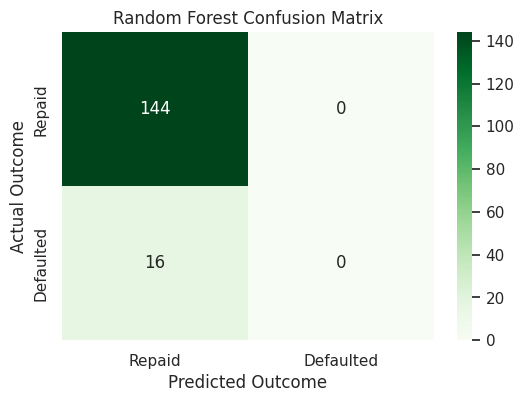

In [ ]:
# Generate Random Forest confusion matrix
rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Repaid", "Defaulted"],
    yticklabels=["Repaid", "Defaulted"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

The confusion matrix shows that Random Forest correctly classified all 144 borrowers who repaid their loans but incorrectly classified all 16 actual defaulters as non-defaulters.

Although this produced 90% accuracy, the model failed to detect any defaults. This would be a serious limitation for a microfinance institution seeking to identify borrowers at risk of default.

## Investigate feature importance

One disadvantage of Random Forest is that its predictions are not as directly interpretable as Logistic Regression coefficients.

We can use permutation importance to investigate which predictors contribute most to predictive performance.

We will calculate importance on the training data using cross-validated permutation importance, avoiding additional model selection based on the test set.

,Feature,Importance
6,Previous_Defaults,0.1571
5,Credit_History_Length,0.1193
4,Loan_Term,0.0244
2,Income_Variance,0.0227
1,Monthly_Income,0.0065
3,Loan_Amount,-0.0009
0,Age,-0.0065


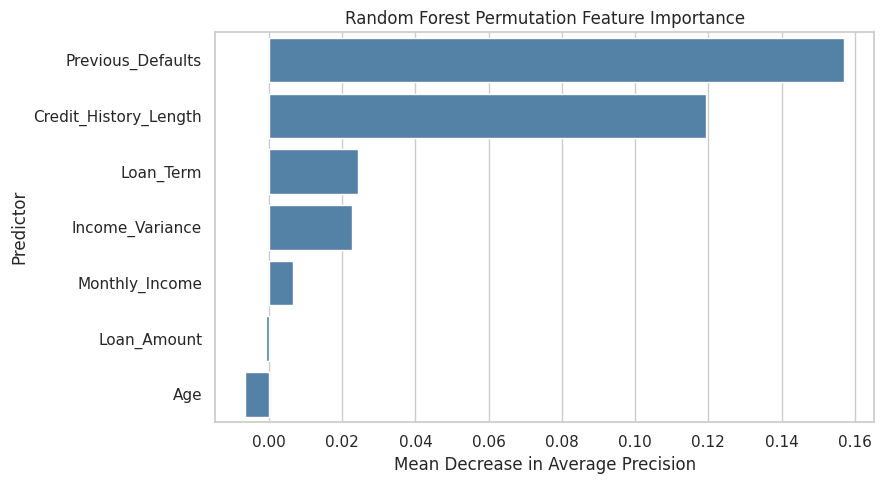

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone

# Collect permutation importances across validation folds
importance_results = []

for train_idx, val_idx in cv.split(X_train, y_train):

    # Fit a copy of the selected model
    fold_model = clone(rf_best)

    fold_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    # Calculate importance on held-out fold
    result = permutation_importance(
        fold_model,
        X_train.iloc[val_idx],
        y_train.iloc[val_idx],
        scoring="average_precision",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    importance_results.append(result.importances_mean)

# Average importance across folds
importance_values = np.mean(importance_results, axis=0)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_values
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

# Plot feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Random Forest Permutation Feature Importance")
plt.xlabel("Mean Decrease in Average Precision")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()

Permutation importance identified Previous Defaults (0.1571) and Credit History Length (0.1193) as the most influential predictors of Random Forest performance.

This is consistent with our Logistic Regression results, where both variables were statistically significant.

Income Variance and Loan Term made smaller positive contributions, while Age and Loan Amount had slightly negative importance values, suggesting that they contributed little useful predictive information in this evaluation.

These results measure contributions to predictive performance rather than causal effects.

## comparison with Logistic Regression

In [ ]:
# Compare Logistic Regression and Random Forest
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Average Precision"
    ],

    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob),
        average_precision_score(y_test, y_prob)
    ],

    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0),
        roc_auc_score(y_test, rf_prob),
        average_precision_score(y_test, rf_prob)
    ]
})

display(comparison.round(4))

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8938,0.9000
1,Precision,0.4000,0.0000
2,Recall,0.1250,0.0000
3,F1-score,0.1905,0.0000
4,ROC-AUC,0.7010,0.7279
5,Average Precision,0.2692,0.3393


Random Forest achieved slightly higher accuracy (90% versus 89.38%), ROC-AUC (0.7279 versus 0.7010), and Average Precision (0.3393 versus 0.2692) compared with Logistic Regression.

However, Logistic Regression identified 12.5% of actual defaults, while Random Forest identified none at the 0.5 threshold.

These findings suggest that Random Forest provides somewhat better risk ranking, but this improvement does not translate into better default classification at the current threshold.

Therefore, the results do not provide sufficient evidence to conclude that Random Forest is the more suitable model for deployment.


But, given the class imbalance and poor default recall, neither model is currently suitable for automated lending decisions without further evaluation and appropriate threshold selection.

# Task 6: Model Comparison and Recommendation

We have now fitted and evaluated both Logistic Regression and Random Forest.

Our final task is to compare them and recommend the most suitable approach for the microfinance institution.

Before making our final recommendation, we'll conduct one additional evaluation: classification threshold analysis.

This is important because neither model identified defaults reliably using the default threshold of 0.5.


From the previous task, we obtained the following results:

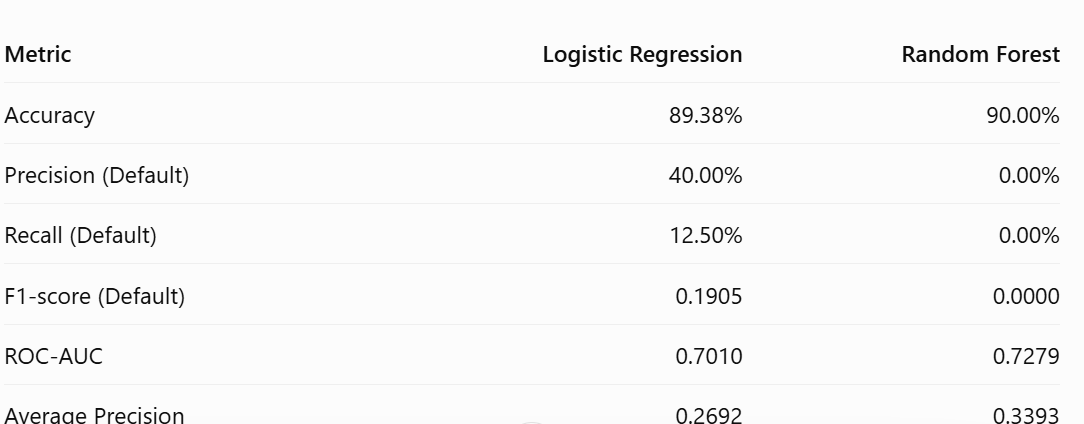



Our main observation is that Random Forest has better risk-ranking metrics, but Logistic Regression identifies more actual defaulters at the 0.5 classification threshold.

We cannot recommend either model based on accuracy alone.

### Generate cross-validated probabilities
We'll use an unpenalized Logistic Regression pipeline to approximate our earlier statsmodels model, and the tuned Random Forest

In [38]:
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

# Logistic Regression with preprocessing inside each fold
lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty=None,
        max_iter=2000,
        random_state=42
    )
)

# Obtain out-of-fold probabilities using training data only
lr_cv_prob = cross_val_predict(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

rf_cv_prob = cross_val_predict(
    clone(rf_best),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Cross-validated probabilities generated successfully.")

Cross-validated probabilities generated successfully.


I generated out-of-fold predicted probabilities using stratified cross-validation on the training dataset. This provides a basis for selecting classification thresholds without directly using the test data for threshold optimization.

The probabilities were successfully generated for both Logistic Regression and Random Forest.

## Select thresholds using F2-score
We will use the F2-score, which places more emphasis on recall than precision.

This makes sense for evaluating default detection, although actual lending deployment would require the institution's financial costs of false positives and false negatives.

In [39]:
from sklearn.metrics import fbeta_score

# Candidate classification thresholds
thresholds = np.arange(0.05, 0.51, 0.01)

def evaluate_thresholds(y_true, probabilities):
    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        results.append({
            "Threshold": threshold,
            "Precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "F2": fbeta_score(
                y_true, predictions,
                beta=2,
                zero_division=0
            )
        })

    return pd.DataFrame(results)

# Evaluate both models
lr_threshold_results = evaluate_thresholds(y_train, lr_cv_prob)
rf_threshold_results = evaluate_thresholds(y_train, rf_cv_prob)

# Select the threshold with the highest F2-score
lr_best_threshold = lr_threshold_results.loc[
    lr_threshold_results["F2"].idxmax(), "Threshold"
]

rf_best_threshold = rf_threshold_results.loc[
    rf_threshold_results["F2"].idxmax(), "Threshold"
]

print("Selected Logistic Regression threshold:",
      round(lr_best_threshold, 2))

print("Selected Random Forest threshold:",
      round(rf_best_threshold, 2))

print("\nLogistic Regression best training-CV result:")
display(lr_threshold_results.loc[
    [lr_threshold_results["F2"].idxmax()]
].round(4))

print("\nRandom Forest best training-CV result:")
display(rf_threshold_results.loc[
    [rf_threshold_results["F2"].idxmax()]
].round(4))

Selected Logistic Regression threshold: 0.07
Selected Random Forest threshold: 0.11

Logistic Regression best training-CV result:


,Threshold,Precision,Recall,F2
2,0.07,0.1582,0.7231,0.4219



Random Forest best training-CV result:


,Threshold,Precision,Recall,F2
6,0.11,0.2242,0.5692,0.4353


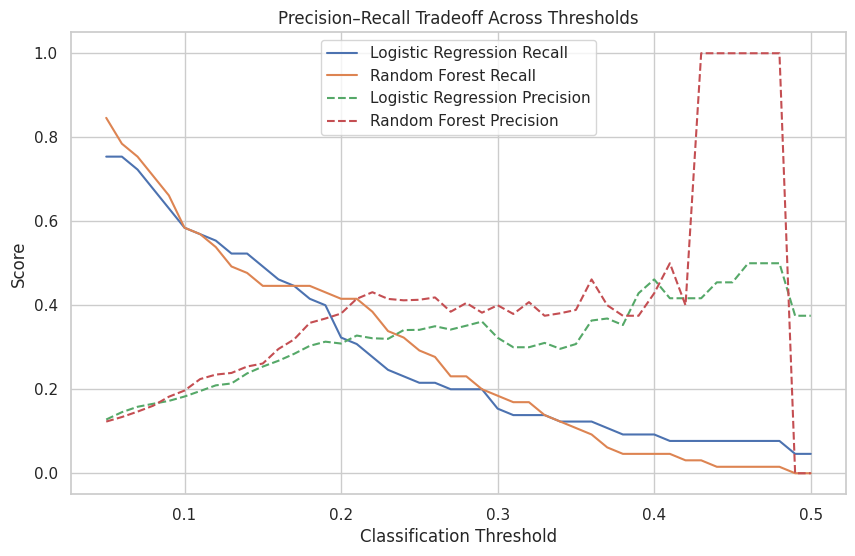

In [40]:
plt.figure(figsize=(10, 6))

plt.plot(
    lr_threshold_results["Threshold"],
    lr_threshold_results["Recall"],
    label="Logistic Regression Recall"
)

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["Recall"],
    label="Random Forest Recall"
)

plt.plot(
    lr_threshold_results["Threshold"],
    lr_threshold_results["Precision"],
    linestyle="--",
    label="Logistic Regression Precision"
)

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["Precision"],
    linestyle="--",
    label="Random Forest Precision"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision–Recall Tradeoff Across Thresholds")
plt.legend()
plt.grid(True)
plt.show()

Using the F2-score, which gives greater weight to recall, the selected classification threshold was 0.07 for Logistic Regression and 0.11 for Random Forest.

At these thresholds, Logistic Regression achieved a cross-validation recall of 72.31%, while Random Forest achieved 56.92%. However, Random Forest obtained a slightly higher F2-score (0.4353 compared with 0.4219), reflecting a better balance between precision and recall under this metric.

These findings suggest that reducing the classification threshold may improve default detection for both models.

The threshold comparison plots illustrate the trade-off between precision and recall. Lower classification thresholds generally improve recall by identifying more potential defaulters, but they also increase the number of borrowers incorrectly classified as likely to default.

This demonstrates why the standard 0.5 threshold may not be appropriate for our imbalanced credit risk dataset. Threshold selection should consider the institution's objectives and the consequences of different classification errors.

In [41]:
# Generate predictions at selected thresholds
lr_adjusted_pred = (y_prob >= lr_best_threshold).astype(int)
rf_adjusted_pred = (rf_prob >= rf_best_threshold).astype(int)

def classification_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "F2-score": fbeta_score(
            y_true, y_pred, beta=2, zero_division=0
        )
    }

# Build comparison table
adjusted_comparison = pd.DataFrame({
    "Logistic Regression": classification_metrics(
        y_test, lr_adjusted_pred
    ),
    "Random Forest": classification_metrics(
        y_test, rf_adjusted_pred
    )
})

display(adjusted_comparison.round(4))

print("Logistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, lr_adjusted_pred))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_adjusted_pred))

,Logistic Regression,Random Forest
Accuracy,0.5375,0.7312
Precision,0.1548,0.2128
Recall,0.8125,0.6250
F1-score,0.2600,0.3175
F2-score,0.4392,0.4505


Logistic Regression Confusion Matrix:
[[73 71]
 [ 3 13]]

Random Forest Confusion Matrix:
[[107  37]
 [  6  10]]


After threshold adjustment, Logistic Regression achieved a recall of 81.25%, correctly identifying 13 of the 16 actual defaulters. Random Forest achieved a recall of 62.5%, identifying 10 defaulters.

However, Logistic Regression generated considerably more false positives, incorrectly classifying 71 borrowers who repaid as likely defaulters, compared with 37 for Random Forest.

Random Forest achieved higher accuracy (73.12%), precision (21.28%), F1-score (0.3175), and F2-score (0.4505). This suggests that Random Forest provides a more balanced classification outcome at the selected thresholds, while Logistic Regression prioritizes identifying more actual defaults.

The results demonstrate that threshold adjustment substantially improves default detection, although both models still produce considerable classification errors.


## Model Comparison

| Criterion | Logistic Regression (Parametric) | Random Forest (Non-Parametric) |
|---|---|---|
| **Assumptions** | Assumes a specified functional form, including linearity in the log-odds. <br> Diagnostics did not establish major violations. | Does not require linearity in the log-odds or a <br> prespecified functional relationship. |
| **Interpretability** | High. Coefficients and odds ratios explain associations with default risk. | Lower. Feature importance provides insight but does not directly estimate effects. |
| **Robustness** | Potentially sensitive to influential observations and model misspecification. | Relatively robust to extreme predictor magnitudes, <br>  but affected by noisy data and class imbalance. |
| **Generalization Risk** | Simpler model with lower complexity, but may underfit complex relationships. | Ensemble learning reduces variance compared with a single tree,  <br> although overfitting remains possible. |
| **Deployment Suitability** | Easier to explain, audit, and maintain. Default detection remains inadequate. | Useful for risk ranking but more <br> complex to explain and currently has inadequate default detection. |







# Final Model Recommendation

I would recommend Logistic Regression as the institution's initial model based on the following statistical evidence:

- Assumption validity: The likelihood ratio test comparing linear and spline specifications was not significant (p = 0.750), indicating insufficient evidence that adding non-linear terms improves model fit. All VIF values were below 5, suggesting no problematic multicollinearity.

- Default detection: At the adjusted threshold, Logistic Regression achieved 81.25% recall, identifying 13 of 16 defaulters, compared with Random Forest's 62.50% (10 of 16).

- Interpretability: Logistic Regression identified statistically significant associations involving Credit History Length, Previous Defaults, and Loan Term, allowing their effects to be quantified using odds ratios.

Random Forest would be preferable if reducing false positives and achieving a better precision–recall balance were the institution's priorities. It produced 37 false positives compared with Logistic Regression's 71, and achieved higher ROC-AUC (0.7279 versus 0.7010), Average Precision (0.3393 versus 0.2692), and adjusted F2-score (0.4505 versus 0.4392).


In the final analysis however, I think the evidence does not establish that non-parametric modeling is necessary. Logistic Regression is statistically defensible and detects more defaults, although Random Forest offers a better balance between detecting defaults and avoiding false alarms. These differences are based on a small test set containing only 16 defaults, so further validation is required before either model is deployed.